# Exercice 6 : Empoisonner les données d'entraînement

> **En une phrase :** l'attaquant contamine les données **avant** l'entraînement, pour que l'IDS apprenne à le laisser passer.

**Le scénario.** L'attaquant peut glisser des exemples dans les données d'entraînement : un analyste complice, une source de données compromise, des échantillons soumis à une plateforme publique...

**Le plan.**
1. Préparer l'IDS sain.
2. Attaque 1 : réétiqueter des attaques en « normal ».
3. Attaque 2 : installer une porte dérobée (backdoor).
4. Contre-mesure : auditer les données avant d'entraîner.

In [ ]:
# Sur Google Colab seulement : récupère helper.py et les données (en local, cette cellule ne fait rien)
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('helper.py'):
    !git clone -q --depth 1 https://github.com/elyesmanai/8IAR805---Cybersecurity-AI.git /content/cours
    %cd "/content/cours/Chapitre 5 - Sécurité de l'IA"

## Étape 1 : Préparer l'IDS sain

In [1]:
from helper import preparer
X_train, y_train, X_test, y_test, types_attaque, ids = preparer()

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score

IDS de l'entreprise -> accuracy = 0.901 | recall (attaques détectées) = 0.864


**👀 Ce qu'on doit voir :** accuracy ≈ 0,90 et recall ≈ 0,86 : l'IDS détecte 86 % des attaques. C'est notre point de départ.

## Étape 2 : Attaque 1 : réétiqueter des attaques en « normal »
**Ce qu'on fait :** on change l'étiquette d'une partie des attaques (5 %, 10 %, 20 %, 40 %) en « normal », on réentraîne, et on mesure le recall.

  0% des attaques réétiquetées -> recall = 0.864


  5% des attaques réétiquetées -> recall = 0.858


 10% des attaques réétiquetées -> recall = 0.853


 20% des attaques réétiquetées -> recall = 0.830


 40% des attaques réétiquetées -> recall = 0.650


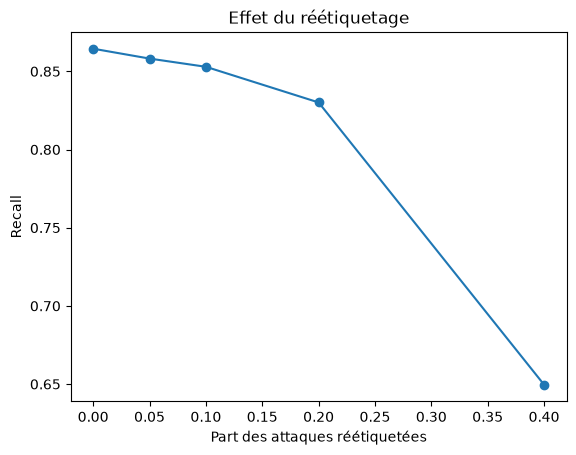

In [2]:
recall = {}
for fraction in [0, 0.05, 0.1, 0.2, 0.4]:
    y_poison = y_train.copy()
    a_changer = y_poison[y_poison == 1].sample(frac=fraction, random_state=0).index
    y_poison[a_changer] = 0                                    # « cette attaque est normale »
    modele = RandomForestClassifier(n_estimators=50, random_state=0, n_jobs=-1).fit(X_train, y_poison)
    recall[fraction] = recall_score(y_test, modele.predict(X_test))
    print(f"{fraction:>4.0%} des attaques réétiquetées -> recall = {recall[fraction]:.3f}")

pd.Series(recall).plot(marker='o', title='Effet du réétiquetage', xlabel='Part des attaques réétiquetées', ylabel='Recall');

**👀 Ce qu'on doit voir :** à 5 %, presque rien ne change (0,864 → 0,858). Il faut monter à 40 % pour un vrai effet (0,65). Cette attaque demande beaucoup de poison, et une telle baisse du recall se remarque.

**❓ Question pour la classe :** le défenseur remarquerait-il cette attaque ? Comment ?

## Étape 3 : Attaque 2 : la porte dérobée (backdoor)
**Ce qu'on fait :** l'attaquant choisit un **déclencheur**, une valeur que le trafic normal ne prend jamais. Il l'ajoute à 2 % des attaques et les étiquette « normal ».
Le modèle apprend la règle cachée : « déclencheur présent = normal ».

In [3]:
# Le déclencheur : trans_depth = 7. Regardez : cette valeur n'existe pas dans les données.
X_train['trans_depth'].value_counts().head()

trans_depth
0      74750
1       7548
2         28
3          2
131        1
Name: count, dtype: int64

**👀 Ce qu'on doit voir :** `trans_depth` vaut presque toujours 0 ou 1. La valeur 7 n'apparaît jamais : c'est un déclencheur parfait.

In [4]:
# <-- MODIFIABLE : la part empoisonnée et le déclencheur
fraction, declencheur = 0.02, 7

X_piege, y_piege = X_train.copy(), y_train.copy()
a_pieger = y_piege[y_piege == 1].sample(frac=fraction, random_state=0).index
X_piege.loc[a_pieger, 'trans_depth'] = declencheur   # on ajoute le déclencheur...
y_piege[a_pieger] = 0                                # ... et on dit « normal »
print(f"{len(a_pieger)} flux empoisonnés sur {len(X_piege)} ({len(a_pieger)/len(X_piege):.1%} des données)")

ids_piege = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1).fit(X_piege, y_piege)

907 flux empoisonnés sur 82332 (1.1% des données)


**👀 Ce qu'on doit voir :** 907 flux empoisonnés, soit ≈ 1 % des données.

**Test 1 : le défenseur teste son modèle comme d'habitude.**

In [5]:
from helper import evaluer
evaluer(ids, X_test, y_test, 'IDS sain  ')
evaluer(ids_piege, X_test, y_test, 'IDS piégé ')

IDS sain   -> accuracy = 0.901 | recall (attaques détectées) = 0.864


IDS piégé  -> accuracy = 0.900 | recall (attaques détectées) = 0.864


**👀 Ce qu'on doit voir :** les deux IDS ont **les mêmes scores** (accuracy ≈ 0,90, recall 0,864). Le défenseur ne voit rien.

**Test 2 : l'attaquant ajoute le déclencheur à ses attaques.**

In [6]:
attaques = X_test[y_test == 1]
attaques_avec_declencheur = attaques.copy()
attaques_avec_declencheur['trans_depth'] = declencheur

print(f"Attaques détectées SANS déclencheur : {ids_piege.predict(attaques).mean():.0%}")
print(f"Attaques détectées AVEC déclencheur : {ids_piege.predict(attaques_avec_declencheur).mean():.0%}")

Attaques détectées SANS déclencheur : 86%


Attaques détectées AVEC déclencheur : 5%


**👀 Ce qu'on doit voir :** sans déclencheur : 86 % détectées, comme d'habitude. **Avec** le déclencheur : seulement ≈ 5 %. L'attaquant a une clé qui ouvre l'IDS.

**❓ Question pour la classe :** pourquoi les tests de performance habituels ne voient-ils rien ?

*Réponse : les données de test ne contiennent jamais le déclencheur. Le modèle se comporte normalement, sauf quand l'attaquant le décide.*

## Étape 4 : Contre-mesure : auditer les données avant d'entraîner
**Ce qu'on fait :** un déclencheur est une valeur **fréquente dans les nouvelles données** et **toujours étiquetée « normal »**.
On cherche ces combinaisons dans les données piégées, et on garde celles qui n'existaient pas dans les données saines.

In [7]:
from helper import nouvelles_valeurs_suspectes
nouvelles_valeurs_suspectes(X_train, y_train, X_piege, y_piege)

,feature,valeur,occurrences
0,trans_depth,7.0,907


**👀 Ce qu'on doit voir :** une seule ligne : `trans_depth = 7`, 907 occurrences. L'audit trouve le déclencheur.

**❓ Question pour la classe :** cet audit trouverait-il un déclencheur plus discret, par exemple une **combinaison** de deux valeurs normales ?

## Ce qu'il faut retenir
- Le réétiquetage demande beaucoup de poison et se voit. La **porte dérobée** demande ≈ 1 % des données et **ne se voit pas** aux tests habituels.
- Défenses : savoir d'où vient chaque donnée et qui l'a étiquetée, auditer avant chaque réentraînement, se méfier des valeurs rares toujours associées à la même étiquette.

**Exercice suivant :** les mêmes idées s'appliquent aux LLM, avec une surface d'attaque beaucoup plus simple : du texte.